# 01 · Raw Overture buildings and places (release 2026-08-19.0)

Step 2: open the map under audit before counting anything. Columns, identifiers, where features come from, which attributes are filled, how big buildings are relative to the 450 sq ft threshold, whether geometries are valid, and whether the point used to place a building in a tract (its bounding-box centre) lies inside the building.

In [1]:
import warnings, os, json, glob
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name in ("eda", "notebooks") else Path.cwd()
os.chdir(ROOT)
import numpy as np, pandas as pd, matplotlib.pyplot as plt, duckdb, pyarrow.parquet as pq
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30); pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
REG = ["maricopa-az", "northern-ca", "eastern-ok", "south-central-tx", "eastern-wa"]
COL = dict(zip(REG, ["#e07b39", "#c0504d", "#6a9e4f", "#3b6fb6", "#8e6bbf"]))

def challenge_root():
    """data/raw/challenge (Windows junctions made by fetch_data.ps1), or the same files in ../MapEquityChallenge/data
    where the junction cannot be followed (e.g. from Linux/WSL)."""
    p = Path("data/raw/challenge")
    try:
        if (p / "reference" / "maricopa-az").is_dir():
            return p
    except OSError:
        pass
    return Path("../MapEquityChallenge/data")
CH = challenge_root(); RAW = Path("data/raw")
TAB, FIG = Path("eda/tables"), Path("eda/figures"); TAB.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
def save(name):
    plt.tight_layout(); plt.savefig(FIG / f"{name}.png", dpi=130, bbox_inches="tight"); plt.show()
con = duckdb.connect(); con.sql("SET threads=4")
study = pd.concat([pd.read_csv(CH / f"reference/{r}/{r}-sample-submission.csv", dtype={"GEOID": str}, usecols=["GEOID"]).assign(region=r) for r in REG])
print("challenge data read from:", CH.resolve(), "| study tracts:", len(study))

challenge data read from: /sessions/rcw-013hmcfk1naa7pch2jpe8lbk/mnt/MapEquityChallenge/data | study tracts: 9794


## 1. Buildings: rows, identifiers, sources and attributes

In [2]:
B = {r: str(CH / f"reference/{r}/{r}-overture-buildings.parquet") for r in REG}
rows = []
for r, f in B.items():
    q = con.sql(f"""SELECT count(*) n, count(DISTINCT id) ids, avg(len(sources)) n_src_mean, avg((len(sources) > 1)::int) multi_src,
          avg(("class" IS NOT NULL)::int) "class", avg((subtype IS NOT NULL)::int) "subtype", avg((height IS NOT NULL)::int) "height",
          avg((num_floors IS NOT NULL)::int) "floors", avg((names.primary IS NOT NULL)::int) "name", avg(is_underground::int) "underground",
          avg(has_parts::int) "has_parts" FROM read_parquet('{f}')""").df().iloc[0]
    rows.append({"region": r, **q})
bo = pd.DataFrame(rows).set_index("region"); bo["duplicate_ids"] = bo.n - bo.ids; bo.to_csv(TAB / "01_buildings_overview.csv")
display(bo.style.format({"n": "{:,.0f}", "ids": "{:,.0f}", "duplicate_ids": "{:,.0f}", "n_src_mean": "{:.2f}"} | {c: "{:.1%}" for c in ["multi_src", "class", "subtype", "height", "floors", "name", "underground", "has_parts"]}))

,n,ids,n_src_mean,multi_src,class,subtype,height,floors,name,underground,has_parts,duplicate_ids
region,,,,,,,,,,,,
maricopa-az,"2,908,224","2,908,224",1.70,70.5%,37.3%,37.9%,80.7%,1.3%,1.1%,0.0%,0.0%,0
northern-ca,"1,164,724","1,164,724",1.39,38.7%,11.5%,11.7%,82.5%,1.6%,0.7%,0.0%,0.0%,0
eastern-ok,"2,551,694","2,551,694",1.19,18.7%,5.6%,5.8%,70.3%,0.3%,0.7%,0.0%,0.0%,0
south-central-tx,"11,463,801","11,463,801",1.36,36.1%,19.5%,19.7%,74.2%,0.4%,0.8%,0.0%,0.0%,0
eastern-wa,"1,081,346","1,081,346",1.43,43.1%,11.9%,12.2%,71.7%,0.7%,1.3%,0.0%,0.0%,0


**Takeaway.** 19.2 million buildings, no duplicate IDs. Buildings carry 1.2-1.7 source records on average; in Maricopa 71% have more than one source, in eastern OK only 19%. Attributes are sparse: height is present for 70-83%, but a use class for only 6-37%, floors and names for under 2%. The class gap is largest in eastern OK (5.6%), the most Microsoft-dependent region; this is the semantic blindness analysed as N4, visible already in the raw file.

## 2. Which dataset supplies each building, and how recent is it?

ds,Esri Community Maps,Google Open Buildings,Microsoft ML Buildings,OpenStreetMap
region,,,,
maricopa-az,4.7%,1.3%,14.3%,79.7%
northern-ca,2.6%,nan%,50.8%,46.6%
eastern-ok,14.0%,nan%,69.4%,16.7%
south-central-tx,2.4%,2.2%,44.3%,51.0%
eastern-wa,6.0%,nan%,38.1%,55.9%


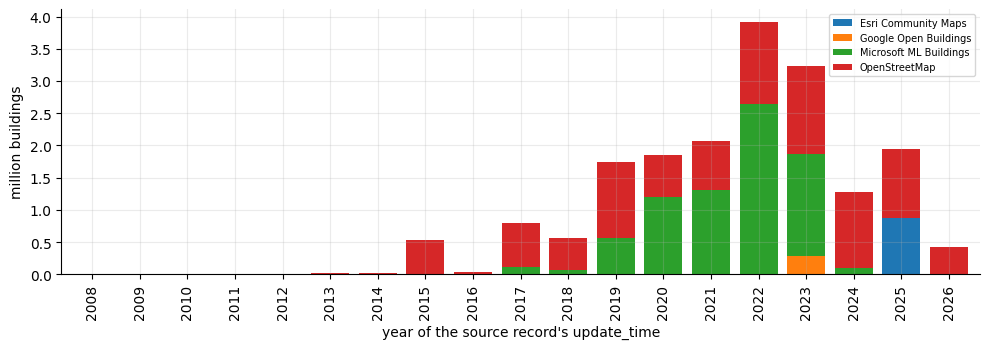

In [3]:
src = con.sql(f"""SELECT regexp_extract(filename, 'reference/([^/]+)/', 1) region, sources[1].dataset ds, left(sources[1].update_time, 4) yr, count(*) n
      FROM read_parquet({list(B.values())}, filename=true) GROUP BY ALL""").df()
s1 = src.pivot_table(index="region", columns="ds", values="n", aggfunc="sum").reindex(REG); s1 = s1.div(s1.sum(axis=1), axis=0)
s1.to_csv(TAB / "01_buildings_first_source.csv"); display(s1.style.format("{:.1%}"))
yr = src.groupby(["ds", "yr"]).n.sum().unstack(0).fillna(0); yr = yr[yr.index.notna() & (yr.index >= "2008")]
fig, ax = plt.subplots(figsize=(10, 3.6)); (yr / 1e6).plot.bar(stacked=True, ax=ax, width=.8)
ax.set_ylabel("million buildings"); ax.set_xlabel("year of the source record's update_time"); ax.legend(fontsize=7); save("01_buildings_update_year")

**Takeaway.** The first-listed source matches the tract-level shares: OSM 80% in Maricopa, Microsoft 69% in eastern OK. Microsoft records were last updated mostly in 2019-2023, OpenStreetMap records are spread through 2015-2026 and Esri's are all from 2025. About 0.7 million Microsoft records carry the date 2000, a placeholder rather than a real update time, so update_time cannot be used to measure how current the map is.

## 3. Building size and the 450 sq ft (41.8 m²) threshold (sample)

,sample,median_m2,under_450sqft,under_20m2,over_1000m2
region,,,,,
maricopa-az,"60,000",219,7.5%,3.4%,1.6%
northern-ca,"60,000",194,6.6%,1.6%,1.4%
eastern-ok,"60,000",174,10.4%,4.6%,1.6%
south-central-tx,"60,000",199,7.7%,3.3%,1.8%
eastern-wa,"60,000",144,13.2%,4.2%,1.3%


,n,median_m2,under_450sqft
ds,,,
Esri Community Maps,"17,816",92,38.6%
Google Open Buildings,"2,079",31,61.0%
Microsoft ML Buildings,"130,281",163,8.5%
OpenStreetMap,"149,824",212,5.4%


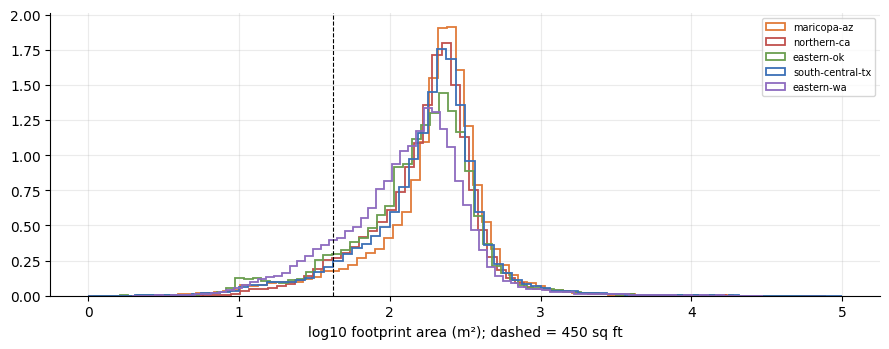

In [4]:
import shapely
from pyproj import Transformer
EA = Transformer.from_crs("EPSG:4326", "EPSG:5070", always_xy=True)
N = 60_000; parts = []
for r, f in B.items():
    s = con.sql(f"SELECT sources[1].dataset ds, geometry, (bbox.xmin + bbox.xmax) / 2 cx, (bbox.ymin + bbox.ymax) / 2 cy FROM read_parquet('{f}') USING SAMPLE {N} ROWS (reservoir, 7)").df()
    g = shapely.from_wkb([bytes(x) for x in s.geometry])
    s["type"] = shapely.get_type_id(g); s["valid"] = shapely.is_valid(g); s["empty"] = shapely.is_empty(g)
    s["area_m2"] = shapely.area(shapely.transform(g, lambda xy: np.column_stack(EA.transform(xy[:, 0], xy[:, 1]))))
    s["centre_inside"] = shapely.contains(g, shapely.points(s.cx, s.cy)) | shapely.touches(g, shapely.points(s.cx, s.cy))
    parts.append(s.drop(columns="geometry").assign(region=r))
smp = pd.concat(parts, ignore_index=True)
sz = smp.groupby("region").agg(sample=("area_m2", "size"), median_m2=("area_m2", "median"), under_450sqft=("area_m2", lambda a: (a < 41.81).mean()),
     under_20m2=("area_m2", lambda a: (a < 20).mean()), over_1000m2=("area_m2", lambda a: (a > 1000).mean())).reindex(REG)
sz.to_csv(TAB / "01_building_size_sample.csv"); display(sz.style.format({"sample": "{:,.0f}", "median_m2": "{:.0f}"} | {c: "{:.1%}" for c in sz.columns[2:]}))
bysrc = smp.groupby("ds").agg(n=("area_m2", "size"), median_m2=("area_m2", "median"), under_450sqft=("area_m2", lambda a: (a < 41.81).mean()))
display(bysrc.style.format({"n": "{:,.0f}", "median_m2": "{:.0f}", "under_450sqft": "{:.1%}"}))
fig, ax = plt.subplots(figsize=(9, 3.6))
for r in REG:
    ax.hist(np.log10(smp.loc[smp.region == r, "area_m2"].clip(1, 1e5)), bins=80, histtype="step", lw=1.3, color=COL[r], label=r, density=True)
ax.axvline(np.log10(41.81), color="k", ls="--", lw=.8); ax.set_xlabel("log10 footprint area (m²); dashed = 450 sq ft"); ax.legend(fontsize=7); save("01_building_area")

**Takeaway.** The median footprint is 144-219 m². In a random sample of 60,000 per region, 6.6-13.2% of buildings are smaller than 450 sq ft (41.8 m²), the same shares the tract-level EDA found removed by the pipeline's filter, which confirms the area calculation. Small structures come mainly from Google (61% under the threshold) and Esri (39%), while Microsoft (8.5%) and OSM (5.4%) footprints are mostly above it.

## 4. Geometry checks and the point used to place each building (same sample)

In [5]:
TYPES = {3: "Polygon", 6: "MultiPolygon"}
gq = smp.groupby("region").agg(polygon=("type", lambda t: (t == 3).mean()), multipolygon=("type", lambda t: (t == 6).mean()),
     invalid=("valid", lambda v: 1 - v.mean()), empty=("empty", "mean"), bbox_centre_outside=("centre_inside", lambda v: 1 - v.mean())).reindex(REG)
gq.to_csv(TAB / "01_geometry_checks.csv"); display(gq.style.format("{:.2%}"))
print("bbox centre outside its own footprint, by source:"); display(smp.groupby("ds").centre_inside.apply(lambda v: 1 - v.mean()).to_frame("share").style.format("{:.2%}"))

,polygon,multipolygon,invalid,empty,bbox_centre_outside
region,,,,,
maricopa-az,100.00%,0.01%,0.00%,0.00%,0.74%
northern-ca,100.00%,0.01%,0.00%,0.00%,0.85%
eastern-ok,99.99%,0.01%,0.00%,0.00%,0.78%
south-central-tx,99.99%,0.01%,0.00%,0.00%,0.77%
eastern-wa,99.98%,0.02%,0.00%,0.00%,0.76%


bbox centre outside its own footprint, by source:


,share
ds,
Esri Community Maps,0.60%
Google Open Buildings,0.24%
Microsoft ML Buildings,0.77%
OpenStreetMap,0.81%


**Takeaway.** Geometries are clean: over 99.98% are single polygons, none are invalid or empty in the sample. The pipeline places each building in a tract by the centre of its bounding box; for 0.7-0.9% of buildings (L-shaped or curved footprints) that point lies outside the building itself. It matters only for buildings within a few metres of a tract boundary, so the effect on counts is negligible, but it is a design choice worth stating (a point-on-surface would be exact).

## 5. Places: rows, categories, confidence, status, sources

,n,ids,no_primary,has_alternate,conf_median,conf_under_05,closed,status_missing,address,website,phone,duplicate_ids
region,,,,,,,,,,,,
maricopa-az,"300,046","300,046",4.9%,57.3%,0.92,10.0%,2.7%,29.6%,100.0%,84.6%,90.4%,0
northern-ca,"116,897","116,897",4.1%,60.9%,0.92,10.3%,2.5%,29.6%,100.0%,83.2%,89.4%,0
eastern-ok,"207,369","207,369",4.1%,62.8%,0.92,9.9%,2.0%,31.9%,100.0%,77.2%,89.6%,0
south-central-tx,"1,300,334","1,300,334",6.1%,59.8%,0.92,12.4%,2.2%,32.5%,100.0%,80.6%,90.5%,0
eastern-wa,"76,491","76,491",4.0%,64.3%,0.92,10.5%,2.0%,31.3%,100.0%,79.4%,87.2%,0


,status,n,share
0,open,"1,319,784",66.0%
1,(missing),"636,146",31.8%
2,permanently_closed,"45,207",2.3%


,ds,n,share
0,meta,"1,211,332",60.5%
1,Microsoft,"328,285",16.4%
2,BrightQuery,"272,988",13.6%
3,Foursquare,"143,949",7.2%
4,AllThePlaces,"31,658",1.6%
5,DAC,"11,651",0.6%
6,PinMeTo,"1,109",0.1%
7,RenderSEO,165,0.0%


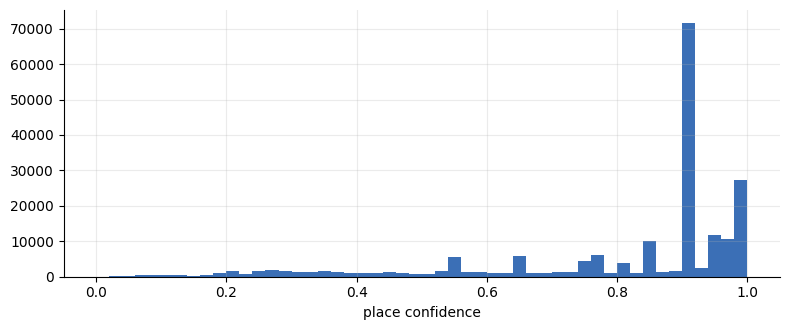

In [6]:
P = {r: str(CH / f"reference/{r}/{r}-overture-pois.parquet") for r in REG}
rows = []
for r, f in P.items():
    q = con.sql(f"""SELECT count(*) n, count(DISTINCT id) ids, avg((categories.primary IS NULL)::int) no_primary,
          avg((coalesce(len(categories.alternate), 0) > 0)::int) has_alternate, median(confidence) conf_median, avg((confidence < .5)::int) conf_under_05,
          avg(coalesce(operating_status = 'permanently_closed', false)::int) "closed", avg((operating_status IS NULL)::int) status_missing,
          avg((coalesce(len(addresses), 0) > 0)::int) "address", avg((coalesce(len(websites), 0) > 0)::int) "website", avg((coalesce(len(phones), 0) > 0)::int) "phone"
          FROM read_parquet('{f}')""").df().iloc[0]
    rows.append({"region": r, **q})
po = pd.DataFrame(rows).set_index("region"); po["duplicate_ids"] = po.n - po.ids; po.to_csv(TAB / "01_places_overview.csv")
display(po.style.format({"n": "{:,.0f}", "ids": "{:,.0f}", "duplicate_ids": "{:,.0f}", "conf_median": "{:.2f}"} | {c: "{:.1%}" for c in ["no_primary", "has_alternate", "conf_under_05", "closed", "status_missing", "address", "website", "phone"]}))
os_ = con.sql(f"SELECT coalesce(operating_status, '(missing)') status, count(*) n FROM read_parquet({list(P.values())}) GROUP BY 1 ORDER BY 2 DESC").df()
os_["share"] = os_.n / os_.n.sum(); display(os_.style.format({"n": "{:,.0f}", "share": "{:.1%}"}))
ps = con.sql(f"SELECT sources[1].dataset ds, count(*) n FROM read_parquet({list(P.values())}) GROUP BY 1 ORDER BY 2 DESC").df(); ps["share"] = ps.n / ps.n.sum()
display(ps.style.format({"n": "{:,.0f}", "share": "{:.1%}"}))
fig, ax = plt.subplots(figsize=(8, 3.4))
cf = con.sql(f"SELECT confidence FROM read_parquet({list(P.values())}) USING SAMPLE 200000 ROWS (reservoir, 7)").df()
ax.hist(cf.confidence, bins=50, color="#3b6fb6"); ax.set_xlabel("place confidence"); save("01_places_confidence")

**Takeaway.** 2.0 million places, no duplicate IDs. 4-6% have no primary category, about 60% list alternate categories, median confidence is 0.92 and 10-12% are below 0.5. 2.0-2.7% are marked permanently closed and are still counted; 32% have no operating status at all. Places come mostly from Meta (60.5%), Microsoft (16.4%) and BrightQuery (13.6%).

## 6. Place categories, and emergency facilities in primary vs alternate

In [7]:
top = con.sql(f"SELECT categories.primary cat, count(*) n FROM read_parquet({list(P.values())}) GROUP BY 1 ORDER BY 2 DESC LIMIT 15").df()
top["share"] = top.n / po.n.sum(); display(top.style.format({"n": "{:,.0f}", "share": "{:.1%}"}))
FAC = {"fire": ["fire_department"], "ems": ["ambulance_and_ems_services"],
       "school": ["elementary_school", "middle_school", "high_school", "school", "private_school", "public_school"]}
rows = []
for k, cats in FAC.items():
    lst = "[" + ",".join(f"'{c}'" for c in cats) + "]"
    q = con.sql(f"""SELECT count(*) FILTER (WHERE list_contains({lst}, categories.primary)) prim,
          count(*) FILTER (WHERE list_has_any(categories.alternate, {lst})) alt,
          count(*) FILTER (WHERE list_has_any(categories.alternate, {lst}) AND NOT coalesce(list_contains({lst}, categories.primary), false)) alt_only
          FROM read_parquet({list(P.values())})""").df().iloc[0]
    rows.append({"facility": k, "primary": q.prim, "in_alternate": q.alt, "alternate_only": q.alt_only, "alternate_only_vs_primary": q.alt_only / max(q.prim, 1)})
fac = pd.DataFrame(rows).set_index("facility"); fac.to_csv(TAB / "01_facility_categories.csv")
display(fac.style.format({"primary": "{:,.0f}", "in_alternate": "{:,.0f}", "alternate_only": "{:,.0f}", "alternate_only_vs_primary": "{:.2f}x"}))

,cat,n,share
0,None,"110,205",5.5%
1,health_and_medical,"44,448",2.2%
2,real_estate_agent,"38,039",1.9%
3,church_cathedral,"37,567",1.9%
4,automotive_repair,"27,975",1.4%
5,beauty_salon,"25,035",1.3%
6,restaurant,"22,991",1.1%
7,landmark_and_historical_building,"22,178",1.1%
8,hair_salon,"21,515",1.1%
9,insurance_agency,"20,340",1.0%


,primary,in_alternate,alternate_only,alternate_only_vs_primary
facility,,,,
fire,"3,641",867,867,0.24x
ems,837,"2,062","2,062",2.46x
school,"24,854","26,937","8,696",0.35x


**Takeaway.** The single most common primary category is no category at all (5.5% of places). For the emergency facilities that matter for exposure, primary-only counts miss a lot: fire departments listed only as an alternate add 24% to the primary count, schools add 35%, and EMS appears 2.5 times as often as an alternate-only category (2,062) as in the primary category (837). Any count of EMS from the primary category alone misses most of them.

## Summary

The raw map is clean as data (no duplicates, valid geometries) but thin as information: most buildings have no use class, places mix closed, uncategorised and low-confidence records, and emergency facilities hide in alternate categories. Building size depends strongly on the source, which is why the 450 sq ft filter is needed before comparing with USA Structures.